# Reproduction of Sanders, Wilson & Gershman (2020)

"Hippocampal remapping as hidden state inference", *eLife* 9:e51140.

This notebook tests the model in `model.py`, then reproduces Figures 2, 3B, 3C, 7B and 9A,
repeats them over 200 seeds, and runs the sensitivity analyses quoted in the review
(Table 1 and the sigma sweep). Run it top to bottom (*Restart & Run All*). Figures are
saved to `figures/` and numbers to `results/`.

If `results/comparison_original.json` is present (from `compare_original.py`), the
released code's values are drawn as crosses on Figures 3C and 7B (and on Figure 2
once that file includes Figure 2).

In [1]:
import csv
import json
import os

import numpy as np
from scipy import integrate, stats
from scipy.special import logsumexp

import model as m

%matplotlib inline

QUICK = False                     # True: 30 seeds instead of 200, 3 instead of 10 per sigma
FIG, RES = "figures", "results"
os.makedirs(FIG, exist_ok=True)
os.makedirs(RES, exist_ok=True)

# Parameters: paper Methods (alpha, normal-Wishart prior); released code
# partitionParams.py (sd = 0.3, means +-1, 15 pairs for Fig 3); morph.py
# (5 vs 25 training pairs, 11 morph probes from -1 to +1).
DEFAULTS = dict(alpha=0.1, sd=0.3, nu0=0.02, kappa0=1e-3, t0=0.02)
FIG3_PAIRS, EARLY, LATE, N_MAX = 15, 5, 25, 40
PROBES = np.linspace(-1, 1, 11)
BAND_SEEDS = range(1, 31 if QUICK else 201)
SWEEP_SEEDS = range(1, 4 if QUICK else 11)

## Tests

Internal-consistency checks on `model.py`. Each cell raises an error if a check fails.

**Eq 2 against numerical integration.** In one dimension the normal-Wishart prior is a
normal-gamma prior: precision $\lambda \sim \text{Gamma}(\nu_0/2, \text{rate}=T_0/2)$ and
$\mu \mid \lambda \sim N(\mu_0, 1/(\kappa_0\lambda))$. A proper prior keeps the integral finite.

In [2]:
obs = m.NormalWishart(mu0=0.0, kappa0=1.0, nu0=3.0, t0=1.0)
Y = np.array([[-0.4], [0.3], [0.9]])

def integrand(mu, lam):
    prior = stats.gamma.pdf(lam, a=1.5, scale=2.0) * stats.norm.pdf(mu, 0.0, 1 / np.sqrt(lam))
    return prior * np.prod(stats.norm.pdf(Y[:, 0], mu, 1 / np.sqrt(lam)))

val, _ = integrate.dblquad(integrand, 0, 60, -15, 15)
assert np.isclose(obs.log_marginal(Y), np.log(val), atol=1e-6)
print("Eq 2 matches numerical integration")

Eq 2 matches numerical integration


**Chained Eq 10 against Eq 2.** $\log p(y_1, \dots, y_n)$ must equal the sum of the
sequential posterior predictives.

In [3]:
rng = np.random.RandomState(0)
for d in (1, 2):
    obs = m.NormalWishart(nu0=d + 1.0, t0=0.5)
    Y = rng.normal(size=(8, d))
    chain = sum(obs.log_predictive(Y[i], Y[:i]) for i in range(len(Y)))
    assert np.isclose(chain, obs.log_marginal(Y))
# also holds for the paper's (improper-looking) hyperparameters in 1-D
obs = m.NormalWishart()
Y = rng.normal(size=(6, 1))
chain = sum(obs.log_predictive(Y[i], Y[:i]) for i in range(len(Y)))
assert np.isclose(chain, obs.log_marginal(Y))
print("chained Eq 10 recovers Eq 2")

chained Eq 10 recovers Eq 2


**Eq 5 against sequential Eq 4.** The CRP probability of a whole partition equals building it up one observation at a time.

In [4]:
alpha = 0.37
z = np.array([0, 0, 1, 0, 2, 1, 1])
seq = sum(m.crp_log_prior_next(z[:i], alpha)[z[i]] for i in range(len(z)))
assert np.isclose(seq, m.crp_log_prob(z, alpha))
print("Eq 5 equals sequential Eq 4")

Eq 5 equals sequential Eq 4


**Eq 5 sums to one** over all partitions of three observations.

In [5]:
alpha = 2.5
parts = [[0, 0, 0], [0, 0, 1], [0, 1, 0], [0, 1, 1], [0, 1, 2]]
assert np.isclose(sum(np.exp(m.crp_log_prob(z, alpha)) for z in parts), 1.0)
print("CRP probabilities sum to one")

CRP probabilities sum to one


**Posteriors are normalised.** Eq 8, and the joint posterior over partitions and probe assignments.

In [6]:
Y, z1, z2 = m.two_context_observations(4)
obs = m.NormalWishart()
assert np.isclose(np.exp(m.state_posterior([0.2], Y, z2, 0.1, obs)).sum(), 1.0)
joint = np.concatenate(m.hypothesis_posterior([0.2], Y, [z1, z2], 0.1, obs))
assert np.isclose(np.exp(joint).sum(), 1.0)
print("posteriors sum to one")

posteriors sum to one


**Eq 11 against Eq 8.** The state evidence ratio is the log odds of an existing state against a new one.

In [7]:
post = m.state_posterior([0.2], Y, z2, 0.1, obs)
assert np.isclose(m.state_evidence_ratio([0.2], Y, z2, 0.1, obs, k=1), post[1] - post[-1])
assert np.isclose(m.state_evidence_ratio([0.2], Y, z2, 0.1, obs), post[:-1].max() - post[-1])
print("Eq 11 matches Eq 8")

Eq 11 matches Eq 8


## Simulation helpers

`fig3_curve` and `morph_curve` compute the quantities plotted in Figures 3C and 7B;
`summarise` reduces one simulated animal to its Figure 3 switch point and whether the
Figure 7B prediction holds.

In [8]:
def make_obs(p):
    return m.NormalWishart(kappa0=p["kappa0"], nu0=p["nu0"], t0=p["t0"])


def data(n_pairs, p, seed, match_original=False):
    burn = m.ORIGINAL_BURN_PER_PAIR if match_original else 0
    return m.two_context_observations(n_pairs, sd=p["sd"], seed=seed, burn_per_pair=burn)


def fig3_curve(Y, z1, z2, p):
    """-Eq 7 (log P(two states) - log P(one state)) after each pair, as in Fig 3C."""
    obs = make_obs(p)
    return np.array([m.partition_evidence_ratio(Y[:2 * n], z2[:2 * n], z1[:2 * n], p["alpha"], obs)
                     for n in range(1, len(Y) // 2 + 1)])


def morph_curve(Y, z1, z2, p):
    """Fig 7B: log [P(S1) + P(S2)] - log [P(D1) + P(D2) + P(D3)] for each probe.
    S1/D1: one state, probe in it / in a new state. S2/D2/D3: two states,
    probe with the square (-1) state / with the circle (+1) state / new."""
    obs = make_obs(p)
    out = []
    for y in PROBES:
        b1, b2 = m.hypothesis_posterior([y], Y, [z1, z2], p["alpha"], obs)
        out.append(np.logaddexp(b1[0], b2[0]) - logsumexp([b1[1], b2[1], b2[2]]))
    return np.array(out)


def crossing(curve):
    """First pair count from which two states are preferred for good (NaN if never)."""
    neg = np.nonzero(curve <= 0)[0]
    if neg.size == 0:
        return 1.0
    return float(neg[-1] + 2) if neg[-1] + 1 < len(curve) else np.nan


def summarise(p, seed):
    """Fig 3 switch point and whether the Fig 7B prediction holds, for one
    simulated animal. The prediction holds when the early curve is positive at
    every probe and the late curve changes sign."""
    Y, z1, z2 = data(N_MAX, p, seed)
    n_star = crossing(fig3_curve(Y, z1, z2, p))
    early, late = (morph_curve(Y[:2 * n], z1[:2 * n], z2[:2 * n], p) for n in (EARLY, LATE))
    holds = bool(early.min() > 0 and late.min() < 0 < late.max())
    return dict(n_star=n_star, holds=holds)


def write_csv(path, rows):
    with open(path, "w", newline="") as f:
        w = csv.DictWriter(f, fieldnames=list(rows[0]))
        w.writeheader()
        w.writerows(rows)


orig_path = os.path.join(RES, "comparison_original.json")
orig = json.load(open(orig_path)) if os.path.exists(orig_path) else {}

## Figure 2: cue constellations

20 four-feature observations from $N(0, 0.2^2)$, then the state evidence ratio (Eq 11,
same state against new state) for four probes. Seed 1 is drawn row by row.

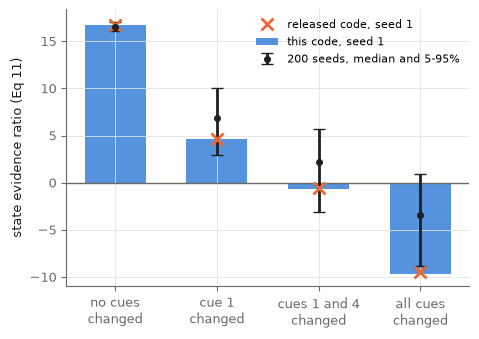

In [9]:
FIG2_TRAIN, FIG2_SD = 20, 0.2
FIG2_PROBES = [("no cues\nchanged", [0, 0, 0, 0]), ("cue 1\nchanged", [1, 0, 0, 0]),
               ("cues 1 and 4\nchanged", [1, 0, 0, 1]), ("all cues\nchanged", [1, 1, 1, 1])]


def fig2_values(seed):
    p = DEFAULTS
    Y = np.random.RandomState(seed).normal(0, FIG2_SD, (FIG2_TRAIN, 4))
    z = np.zeros(FIG2_TRAIN, dtype=int)
    return np.array([m.state_evidence_ratio(np.array(v, dtype=float), Y, z, p["alpha"], make_obs(p), k=0)
                     for _, v in FIG2_PROBES])


f2 = fig2_values(1)
f2_band = np.array([fig2_values(s) for s in BAND_SEEDS])
write_csv(os.path.join(RES, "fig2_seed1.csv"),
          [dict(probe=name.replace("\n", " "), state_evidence_ratio=f2[i],
                seeds_median=np.median(f2_band[:, i]),
                seeds_5=np.percentile(f2_band[:, i], 5), seeds_95=np.percentile(f2_band[:, i], 95))
           for i, (name, _) in enumerate(FIG2_PROBES)])
m.plot_fig2([name for name, _ in FIG2_PROBES], f2, f2_band, orig.get("fig2", {}).get("orig_ratio"),
            os.path.join(FIG, "fig2_reproduction.png"));

## Figure 3: experience-dependent remapping

Observations alternate between a square (mean $-1$) and a circle (mean $+1$). Seed 1 uses
the released code's random stream; the band uses 200 independent seeds.

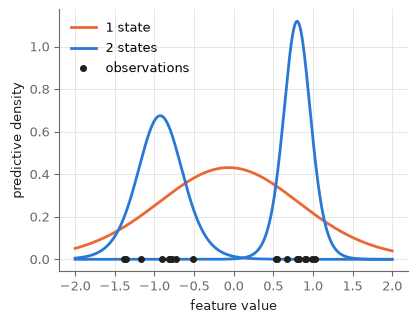

In [10]:
p = DEFAULTS
Y, z1, z2 = data(FIG3_PAIRS, p, 1, match_original=True)
c3 = fig3_curve(Y, z1, z2, p)
c3_band = np.array([fig3_curve(*data(FIG3_PAIRS, p, s), p) for s in BAND_SEEDS])
write_csv(os.path.join(RES, "fig3_seed1.csv"),
          [dict(pairs=i + 1, neg_partition_evidence_ratio=v) for i, v in enumerate(c3)])

# Fig 3B: posterior predictive densities after 10 pairs
Y10, obs = Y[:20], make_obs(p)
x = np.linspace(-2, 2, 801)
one = np.exp([obs.log_predictive([v], Y10) for v in x])
two = [np.exp([obs.log_predictive([v], Y10[k::2]) for v in x]) / 2 for k in (0, 1)]
m.plot_fig3b(x, one, two, Y10[:, 0], os.path.join(FIG, "fig3b_reproduction.png"));

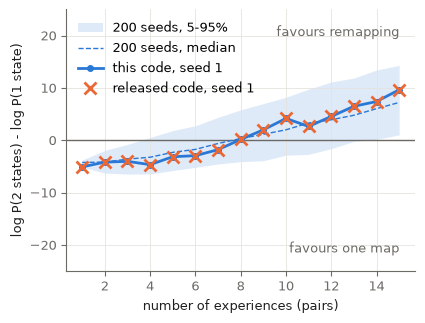

In [11]:
m.plot_fig3c(np.arange(1, FIG3_PAIRS + 1), c3, c3_band, orig.get("fig3", {}).get("orig_ratio"),
             os.path.join(FIG, "fig3c_reproduction.png"));

## Figure 7B: the morph prediction, after 5 and 25 training pairs

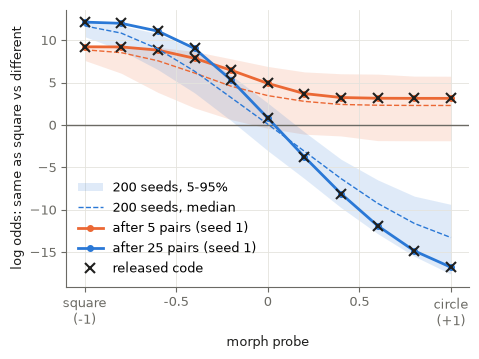

In [12]:
c7, c7_band = {}, {}
for n in (EARLY, LATE):
    c7[n] = morph_curve(*data(n, p, 1, match_original=True), p)
    c7_band[n] = np.array([morph_curve(*data(n, p, s), p) for s in BAND_SEEDS])
write_csv(os.path.join(RES, "fig7_seed1.csv"),
          [dict(probe=x, early_5=c7[EARLY][i], late_25=c7[LATE][i]) for i, x in enumerate(PROBES)])
origs7 = {n: orig["fig7"][str(n)]["orig_ratio"] for n in (EARLY, LATE)} if "fig7" in orig else None
m.plot_fig7(PROBES, c7, c7_band, origs7, os.path.join(FIG, "fig7_reproduction.png"));

## Figure 9A: Figure 3C for three values of alpha (seed 1, as in the released code)

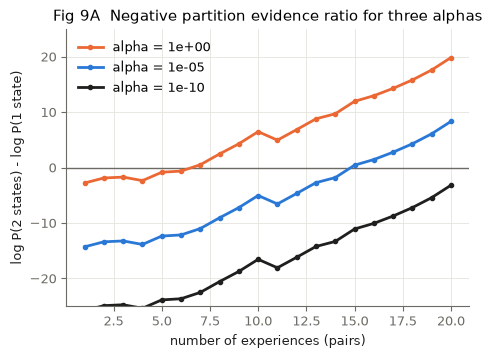

In [13]:
FIG9A_ALPHAS, FIG9A_PAIRS = (1.0, 1e-5, 1e-10), 20
c9 = {a: fig3_curve(*data(FIG9A_PAIRS, dict(DEFAULTS, alpha=a), 1, match_original=True), dict(DEFAULTS, alpha=a))
      for a in FIG9A_ALPHAS}
write_csv(os.path.join(RES, "fig9a_seed1.csv"),
          [dict(pairs=i + 1, **{"alpha_%.0e" % a: c9[a][i] for a in FIG9A_ALPHAS}) for i in range(FIG9A_PAIRS)])
m.plot_fig9a(np.arange(1, FIG9A_PAIRS + 1), c9, os.path.join(FIG, "fig9a_reproduction.png"));

## Table 1: sensitivity of Figure 3C

The seed-1 Figure 3 run with one setting changed: the first pair at which two states are
favoured, and the evidence ratio after 15 pairs in the paper's sign (Eq 7, one state
against two), which is the negative of what Figure 3C plots.

In [14]:
TABLE_SETTINGS = [("published", None), ("alpha", 1e-10), ("alpha", 1e-5), ("alpha", 10.0),
                  ("nu0", 2.0), ("nu0", 10.0), ("kappa0", 1.0), ("kappa0", 10.0)]
table = []
for name, value in TABLE_SETTINGS:
    q = dict(DEFAULTS, **({name: value} if value is not None else {}))
    c = fig3_curve(*data(FIG3_PAIRS, q, 1, match_original=True), q)
    first = np.nonzero(c > 0)[0]
    table.append(dict(param=name, value=value if value is not None else "",
                      first_two_state_pair=int(first[0] + 1) if first.size else "none",
                      evidence_ratio_at_15=round(float(-c[-1]), 1)))
write_csv(os.path.join(RES, "sensitivity_table.csv"), table)
for row in table:
    print(row)

{'param': 'published', 'value': '', 'first_two_state_pair': 8, 'evidence_ratio_at_15': -9.7}
{'param': 'alpha', 'value': 1e-10, 'first_two_state_pair': 'none', 'evidence_ratio_at_15': 11.1}
{'param': 'alpha', 'value': 1e-05, 'first_two_state_pair': 15, 'evidence_ratio_at_15': -0.4}
{'param': 'alpha', 'value': 10.0, 'first_two_state_pair': 2, 'evidence_ratio_at_15': -14.3}
{'param': 'nu0', 'value': 2.0, 'first_two_state_pair': 1, 'evidence_ratio_at_15': -15.3}
{'param': 'nu0', 'value': 10.0, 'first_two_state_pair': 1, 'evidence_ratio_at_15': -18.0}
{'param': 'kappa0', 'value': 1.0, 'first_two_state_pair': 13, 'evidence_ratio_at_15': -3.1}
{'param': 'kappa0', 'value': 10.0, 'first_two_state_pair': 'none', 'evidence_ratio_at_15': 15.4}


## Robustness over seeds and sigma

For each of 200 seeds: the Figure 3 switch point, and whether the Figure 7B prediction
holds. Then the same for each value of sigma, the spread of the observations.

In [15]:
seed_rows = [dict(seed=s, **summarise(DEFAULTS, s)) for s in BAND_SEEDS]
write_csv(os.path.join(RES, "seeds.csv"), seed_rows)

SD_VALUES = np.linspace(0.1, 0.8, 8)
sweep_rows = [dict(sd=v, seed=s, **summarise(dict(DEFAULTS, sd=v), s)) for v in SD_VALUES for s in SWEEP_SEEDS]
write_csv(os.path.join(RES, "sensitivity_sd.csv"), sweep_rows)

## Summary: the numbers quoted in the review

In [16]:
n_star = np.array([r["n_star"] for r in seed_rows])
held = [v for v in SD_VALUES if np.mean([r["holds"] for r in sweep_rows if r["sd"] == v]) >= 0.5]
summary = {
    "defaults": DEFAULTS,
    "fig2_seed1": f2.tolist(),
    "fig2_seeds_median": np.median(f2_band, axis=0).tolist(),
    "fig3_seed1_switch_pair": crossing(c3),
    "fig3_seeds_switch_pair_median": float(np.nanmedian(n_star)),
    "fig3_seeds_switch_pair_5_95": np.nanpercentile(n_star, [5, 95]).tolist(),
    "fig3_seeds_never_switch": int(np.isnan(n_star).sum()),
    "fig7_seed1_early_min": float(c7[EARLY].min()),
    "fig7_seed1_late_range": [float(c7[LATE].min()), float(c7[LATE].max())],
    "fig7_prediction_holds_fraction_of_seeds": float(np.mean([r["holds"] for r in seed_rows])),
    "n_seeds": len(seed_rows),
    "holds_range_sd": [float(min(held)), float(max(held))] if held else None,
}
with open(os.path.join(RES, "summary.json"), "w") as f:
    json.dump(summary, f, indent=1)
print(json.dumps(summary, indent=1))

{
 "defaults": {
  "alpha": 0.1,
  "sd": 0.3,
  "nu0": 0.02,
  "kappa0": 0.001,
  "t0": 0.02
 },
 "fig2_seed1": [
  16.708599832107783,
  4.601349165939839,
  -0.6817007365173691,
  -9.64417090657982
 ],
 "fig2_seeds_median": [
  16.52116476803684,
  6.895835422315217,
  2.2370468811196798,
  -3.434292203850159
 ],
 "fig3_seed1_switch_pair": 8.0,
 "fig3_seeds_switch_pair_median": 8.0,
 "fig3_seeds_switch_pair_5_95": [
  5.0,
  15.0
 ],
 "fig3_seeds_never_switch": 0,
 "fig7_seed1_early_min": 3.1376839741052707,
 "fig7_seed1_late_range": [
  -16.77514565538614,
  12.12915209354566
 ],
 "fig7_prediction_holds_fraction_of_seeds": 0.855,
 "n_seeds": 200,
 "holds_range_sd": [
  0.30000000000000004,
  0.4
 ]
}
